In [3]:
print("Let's Start")


Let's Start


In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [5]:

x , y = make_moons(1000 , noise=0.3 , random_state=1)

In [6]:
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.3 , random_state=42)

In [7]:
model = Sequential()

model.add(Dense(32 , activation='relu'))
model.add(Dense(1 , activation='sigmoid'))

model.compile(loss='binary_crossentropy' , optimizer='Adam' , metrics=['accuracy'])
model.fit(x_train , y_train , epochs=10 , batch_size=32 , validation_data=(x_test , y_test))

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.1902 - loss: 0.8144 - val_accuracy: 0.1900 - val_loss: 0.7626
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3367 - loss: 0.7394 - val_accuracy: 0.5033 - val_loss: 0.6912
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5447 - loss: 0.6763 - val_accuracy: 0.7333 - val_loss: 0.6289
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6916 - loss: 0.6280 - val_accuracy: 0.8300 - val_loss: 0.5763
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7760 - loss: 0.5799 - val_accuracy: 0.8500 - val_loss: 0.5287
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7871 - loss: 0.5396 - val_accuracy: 0.8533 - val_loss: 0.4878
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8051 - loss: 0.5040 - val_accuracy: 0.8533 - val_loss: 0.4549
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7917 - loss: 0.4748 - val_accuracy: 0.8567 - val_los

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step


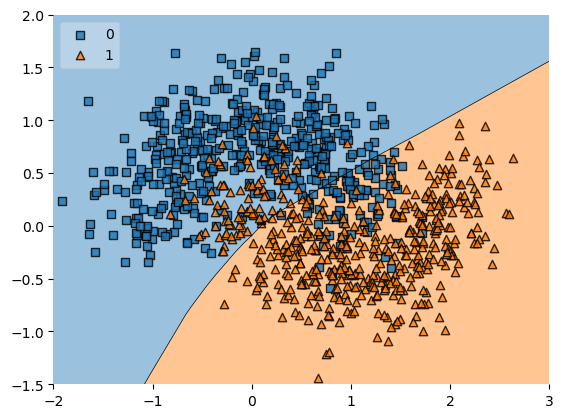

In [12]:
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt
plot_decision_regions(x , y.astype('int') , clf=model , legend=2)
plt.xlim(-2 , 3)
plt.ylim(-1.5 , 2)
plt.show()

Here we will use HyperParameter Tuning using Keras Tuner...
1. how to select appropriate optimizer
2. no. of nodes in a layer
3. how to select no. of layers
4. All in one layer

In [19]:
import keras_tuner as kt

def build_model(hp):
    model = Sequential()

    model.add(Dense(32 , activation='relu'))
    model.add(Dense(1 , activation='sigmoid'))

    optimizer = hp.Choice('optimizer' , values=['adam' , 'sgd'  , 'adadelta'])
    model.compile(optimizer=optimizer , loss='binary_crossentropy' , metrics=['accuracy'])
    return model

In [20]:
tuner = kt.RandomSearch(build_model , objective='val_accuracy' , max_trials=5)
tuner.search(x_train , y_train , epochs=5 , validation_data=(x_test , y_test))

Trial 3 Complete [00h 00m 03s]
val_accuracy: 0.7666666507720947

Best val_accuracy So Far: 0.8399999737739563
Total elapsed time: 00h 00m 11s


In [23]:
tuner.get_best_hyperparameters()[0].values

{'optimizer': 'adam'}

In [24]:
model2= tuner.get_best_models(num_models=1)[0]

c:\Users\Abhishek sharma\anaconda3\Lib\site-packages\keras\src\saving\saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [26]:
model2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129 (516.00 B)

 Trainable params: 129 (516.00 B)

 Non-trainable params: 0 (0.00 B)

In [28]:
model2.fit(x_train , y_train , epochs=50 , validation_data=(x_test , y_test))

Epoch 1/50


22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.7891 - loss: 0.4769 - val_accuracy: 0.8433 - val_loss: 0.4261
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8159 - loss: 0.4390 - val_accuracy: 0.8500 - val_loss: 0.4043
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7843 - loss: 0.4402 - val_accuracy: 0.8533 - val_loss: 0.3877
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7949 - loss: 0.4161 - val_accuracy: 0.8567 - val_loss: 0.3748
Epoch 5/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8143 - loss: 0.3932 - val_accuracy: 0.8567 - val_loss: 0.3636
Epoch 6/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8221 - loss: 0.3986 - val_accuracy: 0.8600 - val_loss: 0.3557
Epoch 7/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8350 - loss: 0.3705 - val_accuracy: 0.8600 - val_loss: 0.3478
Epoch 8/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8117 - loss: 0.3876 - val_accuracy: 0.8667 - val_loss: 0.

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step


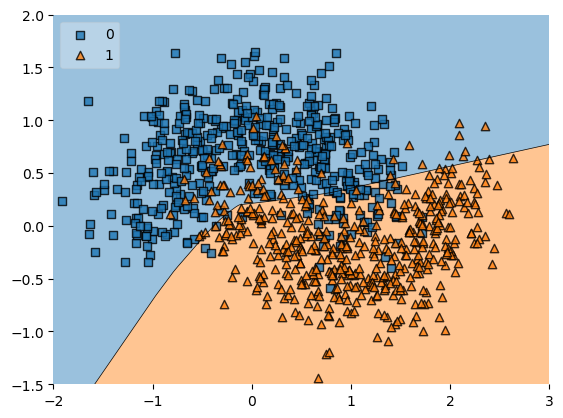

In [29]:
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt
plot_decision_regions(x , y.astype('int') , clf=model2 , legend=2)
plt.xlim(-2 , 3)
plt.ylim(-1.5 , 2)
plt.show()